In [ ]:
from google.colab import drive, userdata
from huggingface_hub import login
import torch

drive.mount("/content/drive")
login(token=userdata.get("HF_TOKEN"))

BASE = "/content/drive/MyDrive/Tesi-Uninsubria"
DATA = f"{BASE}/data"
RESULTS = f"{BASE}/results"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


In [ ]:
from transformers import AutoProcessor, AutoModel

model = AutoModel.from_pretrained("google/medsiglip-448").to(device)
processor = AutoProcessor.from_pretrained("google/medsiglip-448")

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/360 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/809 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  798kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/455 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

In [ ]:
import os
os.makedirs(f"{DATA}/sample", exist_ok=True)
!wget -nc -q -P {DATA}/sample https://storage.googleapis.com/dx-scin-public-data/dataset/images/3445096909671059178.png

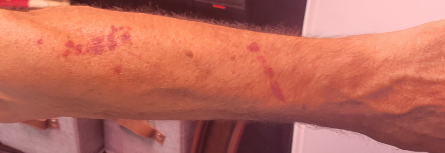

In [ ]:
from PIL import Image

image = Image.open(f"{DATA}/sample/3445096909671059178.png").convert("RGB")
image

In [ ]:
texts = [
    "a photo of an arm with no rash",
    "a photo of an arm with a rash",
    "a photo of a leg with no rash",
    "a photo of a leg with a rash",
]

inputs = processor(text=texts, images=image,
                   padding="max_length", return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)

probs = torch.softmax(outputs.logits_per_image, dim=1)
for text, p in zip(texts, probs[0]):
    print(f"{p:.2%}  {text}")

20.61%  a photo of an arm with no rash
45.16%  a photo of an arm with a rash
12.24%  a photo of a leg with no rash
21.99%  a photo of a leg with a rash
